This file is for calculating the final result from GRMHD simulations and EHT-Imaging.


What is needed:

-   `GRMHD/grmhdDataAfterImageS.npy`
-   `GRMHD/EVPA.npy`
-   `NormR.csv`


# libraries, functions, ...


In [1]:
import numpy as np
from copy import deepcopy
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from utils.libanaly import Plot_Background, plot_quivers, CircleCalc, ImageS
from scipy.linalg import cho_factor, cho_solve

# Part GRMHD: calucate std or cor (without Axion)


What we get:

-   `cor_grmhd` it is a number (rad) representing the standard deviation of different time GRMHD simulations


In [2]:
grmhdDataAfterImageS = np.load(
    "./GRMHD/data_out/grmhdDataAfterImageS_alpha=0.3_res=400.npy"
)
EVPA = np.load("./GRMHD/data_out/EVPA_alpha=0.3_res=400.npy")  # rad
# EVPA_without_axion = EVPA[:, 0, :, :]

In [3]:
# P_without_axion = np.sqrt(
#     grmhdDataAfterImageS[:, 0, :, :, 1] ** 2 + grmhdDataAfterImageS[:, 0, :, :, 2] ** 2
# )

In [3]:
grmhdDataAfterImageS = {}
EVPA = {}
EVPA_1d = {}
EVPA_1d_10deg = {}

for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    grmhdDataAfterImageS[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=100.npy"
    )
    EVPA[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=100.npy")
    EVPA_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=100.npy")
    EVPA_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=100.npy"
    )

grmhdDataAfterImageS_400 = {}
EVPA_400 = {}
EVPA_400_1d = {}
EVPA_400_1d_10deg = {}

for alpha in [0.3]:
    grmhdDataAfterImageS_400[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=400.npy"
    )
    EVPA_400[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=400.npy")
    EVPA_400_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=400.npy")
    EVPA_400_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=400.npy"
    )

In [4]:
rg_per_pixel = 0.51073125
# condition2to9 = np.array(
#     [
#         [
#             2 <= np.sqrt((i - 31.5) ** 2 + (j - 31.5) ** 2) * rg_per_pixel <= 9
#             for j in range(64)
#         ]
#         for i in range(64)
#     ]
# )


# 注意由于这里求的都是不含轴子效应的结果，所以理应与alpha无关
def get_EVPA_diff_xday(diff, alpha=0.3):
    start = 1600
    end = 3000
    grmhd_step = 10
    step = 30  # 30 * 0.1 *8h=1day
    r_step = step // grmhd_step

    diff_x_r_step = int(diff * r_step)
    evpa_diff_temp = np.zeros(((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64))
    evpa_diff_temp_with_condition = np.zeros(
        ((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64)
    )
    EVPA_without_axion = EVPA_400[alpha][:, 0, :, :]
    P_without_axion = np.sqrt(
        grmhdDataAfterImageS_400[alpha][:, 0, :, :, 1] ** 2
        + grmhdDataAfterImageS_400[alpha][:, 0, :, :, 2] ** 2
    )
    for num in range((end - start) // grmhd_step - diff_x_r_step + 1):
        evpa_diff_temp[num] = CircleCalc.circle_sub_evpa(
            EVPA_without_axion[num + diff_x_r_step], EVPA_without_axion[num]
        )
        # condition = (
        #     P_without_axion[num + diff_x_r_step] > P_without_axion[num].max() * 0.1
        # ) * (
        #     P_without_axion[num] > P_without_axion[num].max() * 0.1
        # )  # can be optimized
        # evpa_diff_temp_with_condition[num] = evpa_diff_temp[num] * condition
        # evpa_diff_temp_with_condition[num][
        #     evpa_diff_temp_with_condition[num] == 0
        # ] = np.nan
    return evpa_diff_temp, evpa_diff_temp_with_condition


def get_EVPA_diff_1day(**kwargs):
    return get_EVPA_diff_xday(1, **kwargs)


def get_EVPA_diff_8h(**kwargs):
    return get_EVPA_diff_xday(1 / 3, **kwargs)

In [5]:
evpa_diff, evpa_diff_with_condition = get_EVPA_diff_1day()

In [7]:
# def gaussian(x, amplitude, mean, stddev):
#     return (
#         amplitude
#         / np.sqrt(2 * np.pi)
#         / stddev
#         * np.exp(-(((x - mean) / stddev) ** 2) / 2)
#     )


# def _gaussian_noAmp(x, mean, sigma):
#     return gaussian(x, 1, mean, sigma)


# def plot_gaussian1(
#     data_temp,
#     bins=100,
#     plot_range=(-7, 7),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 16),
# ):

#     # 生成随机数据
#     np.random.seed(42)
#     data = deepcopy(data_temp)
#     if rm_nan == True:
#         data = data[np.isfinite(data)]

#     # 生成直方图
#     hist, bin_edges = np.histogram(data, bins=bins, density=True)
#     bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

#     # 初始猜测值
#     # initial_guess = initial_guess

#     # 使用curve_fit进行拟合
#     params, covariance = curve_fit(
#         gaussian, bin_centers, hist, p0=initial_guess, maxfev=5000000
#     )

#     if plot == True:
#         # 绘制直方图
#         fig = plt.figure(figsize=figsize)
#         plt.hist(data, bins=bins, density=True, range=plot_range, color="orange")

#         # 绘制拟合曲线
#         x_range = np.linspace(*plot_range, 100)
#         fit_curve = gaussian(x_range, *params)
#         # "$y="+f"{params[0]:.3f}"+r"\exp{\frac{x-"+f"{params[1]:.3f}"+r"^2}{2\cdot "+f"{params[2]:.3f}"+"^2}}$"
#         plt.plot(
#             x_range,
#             fit_curve,
#             "r-",
#             label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "
#             + f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",
#             color="brown",
#         )
#         plt.xticks(fontsize=24)
#         plt.yticks(fontsize=24)
#         # plt.xlabel(r"$\frac{\Delta I_{\left("+f"{day}"+r"\mathrm{day}\right)}}{I}$",fontsize=30)
#         # plt.xlabel(r"$\Delta EVPA _{\left("+f"{day}"+r"\mathrm{day}\right)}$",fontsize=24)
#         plt.gca().spines["top"].set_visible(False)
#         plt.gca().spines["right"].set_visible(False)
#         plt.legend(fontsize=24)
#         plt.show()

#     return params, covariance

In [8]:
# plt.imshow(evpa_diff_with_condition[10], cmap="jet")
# plt.colorbar()

In [9]:
# plt.imshow(evpa_diff_with_condition[0], cmap="jet")
# plt.colorbar()

In [6]:
from utils.libanaly import plot_gaussian, fit_gaussian2

badfit, inf, 0.0 * 0.2


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: divide by zero encountered in scalar divide
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:67: RuntimeWarning: divide by zero encountered in divide
  * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: invalid value encountered in multiply
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:232: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = optimize.curve_fit(
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:98: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim(xmin, xmax)
/home/canoziia/MyProject/PHYS/EHT_ZC/.pixi/envs/default/lib/python3.12/site-packages/scipy/stats/_distn_infrastructure.py:2027: RuntimeWarning: invalid value encountered in divide
  x = np.asarray((x - loc)/scal

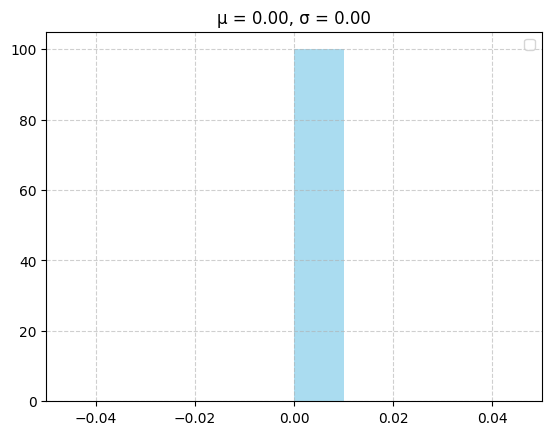

In [7]:
_, _cor_grmhd_tmp_ = fit_gaussian2(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    rm_nan=True,
    bins=100,
    threshold=0.2,
)

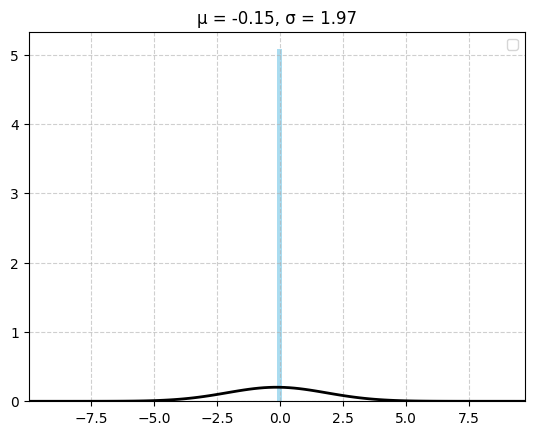

In [8]:
plot_gaussian(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    bins=100,
    mean=-0.147,
    sigma=1.97,
)

In [13]:
# _cor_grmhd_tmp_ = plot_gaussian1(
#     evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
#     bins=100,
#     plot_range=(-7, 7),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )[0][2]

In [9]:
cor_grmhd = np.identity(64 * 64) * (_cor_grmhd_tmp_ / 180 * np.pi) ** 2

In [10]:
def make_interpolator(axion_evpa_diffs_std_16phase):
    """
    给定一个 {alpha: ndarray(16,64,64)} 的字典，
    返回一个插值函数 f(alpha)，输出线性插值结果。
    """
    # 提取并排序 alpha 值
    alphas = np.array(sorted(axion_evpa_diffs_std_16phase.keys()))

    # 将数据堆叠为 (N_alpha, 16, 64, 64)
    data = np.stack([axion_evpa_diffs_std_16phase[a] for a in alphas])

    def f(alpha):
        # 若超出范围，则截断在边界
        if alpha <= alphas[0]:
            return data[0]
        if alpha >= alphas[-1]:
            return data[-1]

        # 找到相邻区间
        idx = np.searchsorted(alphas, alpha) - 1
        a0, a1 = alphas[idx], alphas[idx + 1]
        w = (alpha - a0) / (a1 - a0)

        # 线性插值
        return (1 - w) * data[idx] + w * data[idx + 1]

    return f

# Part Axion


In [11]:
def _omega(alpha):
    return alpha * (1 - alpha**2 / 2 / (2 + 1 + 1) ** 2)

In [12]:
alpha_grmhd = 0.3
omega_grmhd = _omega(alpha_grmhd)
axion_norm = 0.1  # check it
g_res = 40
gagg = np.logspace(np.log10(1 / 137.0), 2, g_res)

In [18]:
# EVPA_fit_result = np.load("./GRMHD/EVPA_fit_result.npy")  # rad

我们没有跑不同 omega 下的 axion 随 grmhd 演化的效应。因此需要把在 omega=0.4 情况下的 diffs_axion_evpa 结果 rescale 到所有的情况。使用不同 omega 时 photon ring 的半径上的 axion 强度来 rescale。

错误的，现在跑了


In [19]:
# import pandas as pd
# from scipy.interpolate import RegularGridInterpolator


# def load_and_interpolate(csv_file):
#     # 读取CSV文件
#     df = pd.read_csv(csv_file, header=None, names=["omega", "R", "f"])

#     # 获取唯一的omega和R值
#     omega_values = np.unique(df["omega"].values)
#     R_values = np.unique(df["R"].values)

#     # 创建二维插值网格
#     f_values = df.pivot(index="omega", columns="R", values="f").values

#     # 创建插值函数
#     interpolator = RegularGridInterpolator(
#         (omega_values, R_values), f_values, bounds_error=False, fill_value=None
#     )

#     def _f(omega, R):
#         # 计算插值
#         return interpolator((omega, R))

#     return _f

In [20]:
# R_photon_ring = (246 - 157) / 400 * 2 * 23.1131 / 2

In [21]:
# f_axion_norm = load_and_interpolate("NormR.csv")

## every pixel, find sigma of diffs_axion_evpa over every grmhd


In [13]:
EVPA_cos_fit_result = {}
EVPA_cos_fit_result_1d_10deg = {}
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    EVPA_cos_fit_result[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_alpha={alpha}.npy"
    )
    EVPA_cos_fit_result_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_1d_10deg_alpha={alpha}.npy"
    )

In [14]:
from utils.libanaly import fit_gaussian, fit_gaussian2

In [15]:
def b_scaling(alpha):
    return 0.03 * (alpha / 0.05) ** (7 / 4)

In [17]:
extra_phase = np.linspace(0, 2 * np.pi, 16)


def get_A_phi0_params():
    # these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        # EVPA_without_axion = EVPA[alpha][:, 0, :, :]
        P_without_axion = np.sqrt(
            grmhdDataAfterImageS[alpha][:, 0, :, :, 1] ** 2
            + grmhdDataAfterImageS[alpha][:, 0, :, :, 2] ** 2
        )
        # condition = (
        #     P_without_axion > P_without_axion.max(axis=(1, 2))[:, None, None] * 0.1
        # )  # ?*64*64 and 64*64
        A_data_list = EVPA_cos_fit_result[alpha][:, :, :, 0]
        # A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result[alpha][:, :, :, 1]
        # phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=True,
            threshold=np.nan,
            p_value_threshold=0.001,
            bins=20,
            nomean=True,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=True,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=np.nan,
            p_value_threshold=0.001,
            bins=20,
            nomean=True,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_dict, phi0_params_dict = get_A_phi0_params()

# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     for i in range(64):
#         for j in range(64):
#             if np.isnan(A_params_dict[alpha][0, i, j]):
#                 A_params_dict[alpha][0, i, j] = (
#                     A_params_dict[alpha][0, i - 1, j]
#                     + A_params_dict[alpha][0, i + 1, j]
#                     + A_params_dict[alpha][0, i, j - 1]
#                     + A_params_dict[alpha][0, i, j + 1]
#                 ) / 4
#                 A_params_dict[alpha][1, i, j] = (
#                     A_params_dict[alpha][1, i - 1, j]
#                     + A_params_dict[alpha][1, i + 1, j]
#                     + A_params_dict[alpha][1, i, j - 1]
#                     + A_params_dict[alpha][1, i, j + 1]
#                 ) / 4
#             if np.isnan(phi0_params_dict[alpha][0, i, j]):
#                 phi0_params_dict[alpha][0, i, j] = (
#                     phi0_params_dict[alpha][0, i - 1, j]
#                     + phi0_params_dict[alpha][0, i + 1, j]
#                     + phi0_params_dict[alpha][0, i, j - 1]
#                     + phi0_params_dict[alpha][0, i, j + 1]
#                 ) / 4
#                 phi0_params_dict[alpha][1, i, j] = (
#                     phi0_params_dict[alpha][1, i - 1, j]
#                     + phi0_params_dict[alpha][1, i + 1, j]
#                     + phi0_params_dict[alpha][1, i, j - 1]
#                     + phi0_params_dict[alpha][1, i, j + 1]
#                 ) / 4
# np.save("GRMHD/data_out/A_params_dict_nonan.npy", A_params_dict, allow_pickle=True)
# np.save(
#     "GRMHD/data_out/phi0_params_dict_nonan.npy", phi0_params_dict, allow_pickle=True
# )

# raise KeyboardInterrupt

np.save("GRMHD/data_out/A_params_dict.npy", A_params_dict, allow_pickle=True)
np.save("GRMHD/data_out/phi0_params_dict.npy", phi0_params_dict, allow_pickle=True)
A_params_interpolator = make_interpolator(A_params_dict)
phi0_params_interpolator = make_interpolator(phi0_params_dict)


def axion_evpa_diffs_16phase_1(alpha):
    # 这里给的是振幅为ga=axion_norm*1/2/pi， 2pi g a=2pi g f axion_norm=axion_norm 时的结果，所以左右除以axion_norm后就是2pi g f=1时的结果。最终求限制的时候，2pi g f从1/137到2，对应了2pi g a=2pi g b f=这个值*(1/137,2)*b
    # 因此在那里要乘以gagg[g]再乘以b_scaling(alpha)，或者把b在这里乘掉。b越小，导致理论变化值越小，限制越弱。或者说理论预言： 2pi g b f=1时会导致1/2/pi的偏转 观测偏转小于1，证明2pi g b f小于2pi，2pi g f小于2pi/b，所以b越小限制越差
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_1


def axion_evpa_diffs_16phase_2(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]

        _axion_evpa_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_2


def axion_evpa_diffs_std_16phase(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_diffs_16phase_1[alpha] = _axion_evpa_diffs_16phase_tmp_1
#     axion_evpa_diffs_16phase_2[alpha] = _axion_evpa_diffs_16phase_tmp_2
#     axion_evpa_diffs_std_16phase[alpha] = _axion_evpa_diffs_std_16phase_tmp

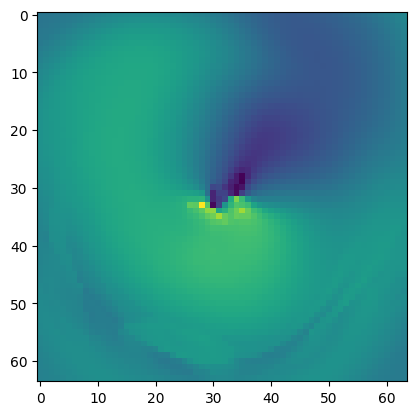

In [18]:
_x = np.zeros((64, 64))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_diffs_16phase_1(alpha)[0]
plt.imshow(_x)

In [ ]:
# extra_phase = np.linspace(0, 2 * np.pi, 16)


# # 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm*gagg[g]
# # first calc 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm
# # and define 2*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)/axion_norm

# condition = (P_without_axion > threshold) * condition2to9  # ?*64*64 and 64*64

# # caution!!! amp should be set
# constant1_axion = (
#     2
#     * np.sin(0.112411 * omega_grmhd / 2 * 24)
#     * np.sin(0.112411 * omega_grmhd / 2 * 6)
#     / (0.112411 * omega_grmhd / 2 * 6)
#     / axion_norm
# )

# diffs_axion_evpa_t = np.zeros((16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2]))
# diffs_axion_evpa_std_t = np.zeros(
#     (16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2])
# )

# A_data_list = deepcopy(EVPA_fit_result[:, :, :, 0]) * condition
# A_data_list[A_data_list == 0] = np.nan
# phi0_data_list = deepcopy(EVPA_fit_result[:, :, :, 1]) * condition
# phi0_data_list[phi0_data_list == 0] = np.nan

In [ ]:
# def fit_gaussian(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     _data = deepcopy(data_list)
#     if rm_nan == True:
#         _data = _data[np.isfinite(_data)]

#     fit_success = False

#     if output:
#         print("------------------fit start-----------------------")

#     for bins in bins_list:
#         if _data.shape[0] < bins:
#             if output:
#                 print("badfit, bins>len(data)")
#             continue
#         hist, bin_edges = np.histogram(_data, bins=bins, density=True)
#         bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
#         initial_guess[0] = 1  # np.shape(_data)[0]
#         initial_guess[1] = bin_centers[np.argmax(hist)]
#         initial_guess[2] = np.std(_data)
#         try:
#             params, covariance = curve_fit(
#                 _gaussian_noAmp, bin_centers, hist, maxfev=maxfev  # p0=initial_guess,
#             )
#         except Exception as e:
#             if output:
#                 print("badfit, error", e)
#             continue
#         # params=np.asarray(params)
#         # covariance=np.asarray(covariance)
#         c1 = abs(covariance[1][1]) / abs(params[1])
#         # c2 = abs(covariance[2][2]) / abs(params[2])
#         # if output:
#         #     print(c1, c2)
#         if c1 < 1:  # and c2 < 1:
#             fit_success = True
#             break
#         else:
#             if output:
#                 print("badfit, cov")
#     if not fit_success:
#         params = np.zeros((3))
#         covariance = np.zeros((3, 3))
#         params[:] = np.nan
#         covariance[:] = np.nan
#     if output:
#         print("fit complete!")
#     return params, covariance


# def fit_gaussian_params(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     params, _ = fit_gaussian(
#         data_list,
#         bins_list=bins_list,
#         initial_guess=initial_guess,
#         rm_nan=rm_nan,
#         maxfev=maxfev,
#         output=output,
#     )
#     return params

In [ ]:
# # 4min
# A_params = np.apply_along_axis(fit_gaussian_params, 0, A_data_list, rm_nan=True)
# phi0_params = np.apply_along_axis(
#     fit_gaussian_params, 0, phi0_data_list, rm_nan=True
# )  # change it

In [ ]:
# # np.save("A_params",A_params)
# # np.save("phi0_params",phi0_params)
# A_params = np.load("A_params.npy")  # amplitude, mean, stddev
# phi0_params = np.load("phi0_params.npy")

In [ ]:
# amp = EVPA_fit_result[51, :, :, 0]
# phi0 = EVPA_fit_result[51, :, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t[i] = constant1_axion * amp * np.sin(ep + phi0)  # *gagg[g]
#     diffs_axion_evpa_std_t[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0) * A_params[2], 2)
#         + np.power(constant1_axion * amp * np.cos(ep + phi0) * phi0_params[2], 2)
#     )
# diffs_axion_evpa = np.mean(diffs_axion_evpa_t, axis=0)  # rad
# diffs_axion_evpa_std = np.mean(diffs_axion_evpa_std_t, axis=0)  # rad

In [ ]:
# A_params.shape

In [ ]:
# np.save("./Plot/diffs_axion_evpa_std.npy", diffs_axion_evpa_std)

In [ ]:
# np.save("./Plot/diffs_axion_evpa.npy", diffs_axion_evpa)

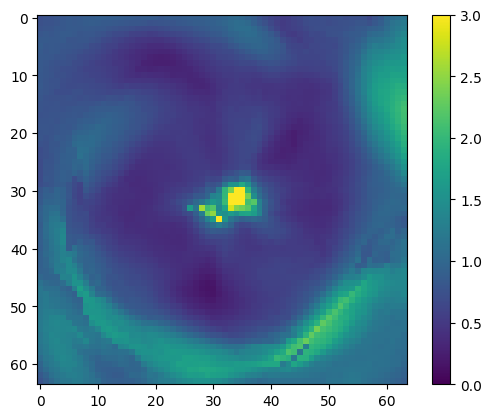

In [19]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase(0.3), axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 3)

In [ ]:
# figure, ax = plt.subplots(figsize=(30, 30))
# Plot_Background(figure, ax, A_params[1] / np.pi * 180)

1d


In [ ]:
# # 141,360,3
# EVPA_fit_result_1d = np.load("./GRMHD/EVPA_fit_result_1d.npy")  # rad

In [20]:
extra_phase = np.linspace(0, 2 * np.pi, 16)
# these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel


def get_A_phi0_1d_params():
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        A_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 0]
        A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 1]
        phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=False,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_1d_dict, phi0_params_1d_dict = get_A_phi0_1d_params()
np.save("GRMHD/data_out/A_params_1d_dict.npy", A_params_1d_dict, allow_pickle=True)
np.save(
    "GRMHD/data_out/phi0_params_1d_dict.npy", phi0_params_1d_dict, allow_pickle=True
)
A_params_1d_interpolator = make_interpolator(A_params_1d_dict)
phi0_params_1d_interpolator = make_interpolator(phi0_params_1d_dict)


def axion_evpa_1d_diffs_16phase_1(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_1


def axion_evpa_1d_diffs_16phase_2(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_2


def axion_evpa_1d_diffs_std_16phase(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_1d_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     # caution!!! amp should be set
#     constant1_axion = (
#         2
#         * np.sin(0.112411 * _omega(alpha) / 2 * 24)
#         * np.sin(0.112411 * _omega(alpha) / 2 * 6)
#         / (0.112411 * _omega(alpha) / 2 * 6)
#         / axion_norm
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_1d_diffs_16phase_1[alpha] = _axion_evpa_1d_diffs_16phase_tmp_1
#     axion_evpa_1d_diffs_16phase_2[alpha] = _axion_evpa_1d_diffs_16phase_tmp_2
#     axion_evpa_1d_diffs_std_16phase[alpha] = _axion_evpa_1d_diffs_std_16phase_tmp

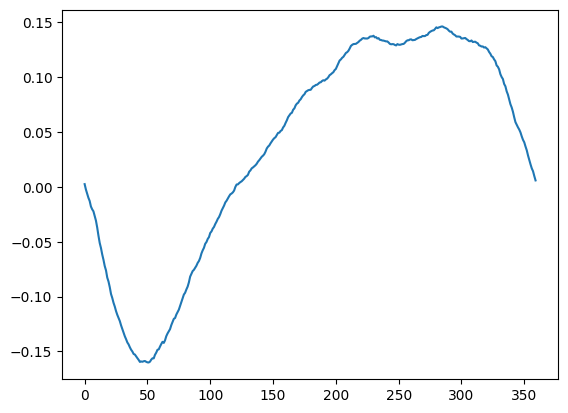

In [21]:
_x = np.zeros((360,))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_1d_diffs_16phase_1(alpha)[0, :]
plt.plot(_x)

In [ ]:
# diffs_axion_evpa_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))
# diffs_axion_evpa_std_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))

# A_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 0])
# A_data_list_1d[A_data_list_1d == 0] = np.nan
# phi0_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 1])
# phi0_data_list_1d[phi0_data_list_1d == 0] = np.nan

In [ ]:
# 2min
# A_params_1d=np.apply_along_axis(fit_gaussian_params,0,A_data_list_1d,rm_nan=True)
# phi0_params_1d=np.apply_along_axis(fit_gaussian_params,0,phi0_data_list_1d,rm_nan=True) # change it

In [ ]:
# # np.save("A_params_1d",A_params_1d)
# # np.save("phi0_params_1d",phi0_params_1d)
# A_params_1d = np.load("A_params_1d.npy")  # amplitude, mean, stddev
# phi0_params_1d = np.load("phi0_params_1d.npy")

In [ ]:
# amp_1d = EVPA_fit_result_1d[51, :, 0]
# phi0_1d = EVPA_fit_result_1d[51, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t_1d[i] = (
#         constant1_axion * amp_1d * np.sin(ep + phi0_1d)
#     )  # *gagg[g]
#     diffs_axion_evpa_std_t_1d[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0_1d) * A_params_1d[2], 2)
#         + np.power(
#             constant1_axion * amp_1d * np.cos(ep + phi0_1d) * phi0_params_1d[2], 2
#         )
#     )
# diffs_axion_evpa_1d = np.mean(diffs_axion_evpa_t_1d, axis=0)  # rad
# diffs_axion_evpa_std_1d = np.mean(diffs_axion_evpa_std_t_1d, axis=0)  # rad

# EXPERIMENT


In [22]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy
from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name="test"):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel(r"$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel(r"$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"M_all/new_static/{name}.pdf", dpi=600)


def get_inv(M):
    u, s, v = np.linalg.svd(M)
    return np.dot(u / s, u.T)

# Final


In [23]:
import scipy.stats as stats

In [24]:
def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)  # 只拟合 kappa 和 mu
    return mu_fit / 2

In [25]:
def topset_rank(data_cor, data_std, condition_good):
    sum_of_pixels = np.zeros(1572)
    for i in range(4):
        rmnan_times = np.nan_to_num(data_cor[i] / data_std[i].reshape(4096, 1), nan=0)
        sum_of_pixels += np.sum(
            ((rmnan_times)[np.where((condition_good).reshape(4096))]) ** 2,
            axis=0,
        )
    return sum_of_pixels

In [31]:
condition = np.load("./EHT-Imaging/data_out/condition.npy", allow_pickle=True)

In [ ]:
theta_mean = []
theta_std = []
P_mean = []
I_mean = []
theta_cor = []
badset = []
theta_data_vonmises_list = []
resolution = 64
xy_coord = [(i, j) for i in range(resolution) for j in range(resolution)]


num = 0
data_cor_list = []
for day in [95, 96, 100, 101]:
    with np.load(f"./EHT-Imaging/data_out/{day}.npz") as data:
        theta_mean.append(data["arr_0"])  # rad
        theta_std.append(data["arr_1"])  # rad
        P_mean.append(data["arr_2"] * 6.54737e12)  # ?这个哪来的
        I_mean.append(data["arr_3"] * 6.54737e12)
        # P_mean.append(data['arr_2'])

    All_data = np.load(f"./EHT-Imaging/data_out/{day}_all_data.npy")
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    theta_data[np.isnan(theta_data)] = 0
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data_vonmises_list.append(
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_mean[num]) + theta_mean[num]
    )
    # theta_data=theta_data*180./np.pi # degree

    data_cor = np.zeros((64 * 64, All_data.shape[0]))
    for x in range(len(xy_coord)):
        i, j = xy_coord[x]
        if (
            theta_mean[num][i][j] == 0
            and theta_std[num][i][j] == 0
            or np.isnan(theta_mean[num][i][j])
            or np.isnan(theta_std[num][i][j])
        ):
            badset.append(i * resolution + j)
        # data_cor[x] = (theta_data[i][j]-theta_mean[num][i][j])
        if np.isfinite(theta_mean[num][i][j]):
            pass
        data_cor[x] = CircleCalc.circle_sub_evpa(
            theta_data[:, i, j], theta_mean[num][i, j]
        )
    data_cor_list.append(data_cor)
    num += 1

# sum_of_pixels = topset_rank(data_cor_list, theta_std, condition)

for num in range(4):

    cor_data = np.dot(data_cor_list[num], data_cor_list[num].T) / All_data.shape[0]
    # cor_data = (
    #     np.dot(
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]],
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]].T,
    #     )
    #     / 786
    # )

    theta_cor.append(cor_data)

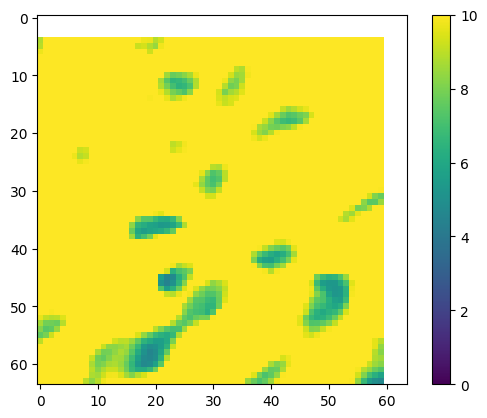

In [ ]:
plt.imshow(theta_std[2] / np.pi * 180)
plt.colorbar()
plt.clim(0, 10)

In [ ]:
# np.save("./EHT-Imaging/data_out/topset_rank_786.npy", np.argsort(sum_of_pixels)[:786])

In [49]:
# def gaussian2(x, *param):
#     mean = param[0]
#     sigma = param[1]
#     amplitude = param[2]
#     return (
#         amplitude
#         / np.sqrt(2.0 * np.pi * sigma * sigma)
#         * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
#     )

In [50]:
# def fit_gaussian2(d1evpaarr, bins_i=4):
#     counts, bins = np.histogram(d1evpaarr, bins=10 * bins_i)  # 10*(4)
#     # counts,bins =re_loc(counts,bins)
#     xarray = np.array([(bins[i] + bins[i + 1]) / 2 for i in range(len(bins) - 1)])
#     try:
#         popt, pcov = optimize.curve_fit(
#             gaussian2, xarray, counts, p0=[vonmises_mean(d1evpaarr), 1, 786]
#         )  # ,maxfev=50000,gtol=1e-10
#     except Exception as e:
#         print(f"badfit, error", e)
#         return np.array([np.nan, np.nan, np.nan])
#     if abs(pcov[0][0]) > abs(popt[0]) or abs(pcov[1][1]) > abs(popt[1]):
#         print(f"badfit")
#         return np.array([np.nan, np.nan, np.nan])
#     else:
#         return np.array([popt[0], np.abs(popt[1]), popt[2]])

In [ ]:
std_786 = []
mean_786 = []
theta_cor = []
num_786 = 786
for num in range(4):
    print(num)
    theta_data_786 = (
        theta_data_vonmises_list[num]
        .reshape(1572, 4096)
        .T[:, np.argsort(sum_of_pixels)[:num_786]]
    )
    tmpres = np.apply_along_axis(
        fit_gaussian2,
        1,
        theta_data_786,
        plot_failed=False,
        angle=True,
        lower_bound=-np.pi / 2,
        upper_bound=np.pi / 2,
        threshold=0.2,
        bins=100,
    )
    mean_786.append(tmpres[:, 0])
    std_786.append(tmpres[:, 1])
    cor_data = CircleCalc.circle_sub_evpa(theta_data_786.T, tmpres[:, 0]).T
    theta_cor.append(np.dot(cor_data, cor_data.T) / num_786)
np.save("./EHT-Imaging/data_out/std_786.npy", std_786, allow_pickle=True)

0


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: divide by zero encountered in scalar divide
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:67: RuntimeWarning: divide by zero encountered in divide
  * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: invalid value encountered in multiply
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:232: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = optimize.curve_fit(


badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf

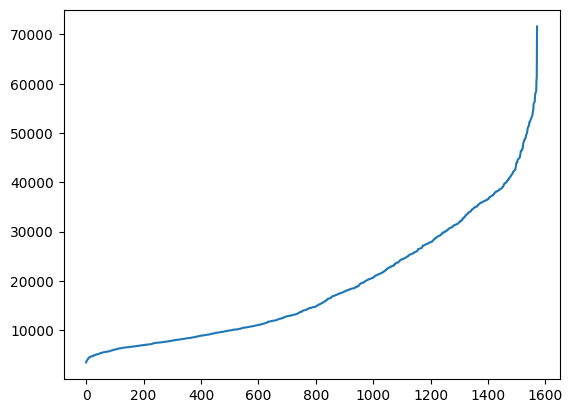

In [13]:
plt.plot(sum_of_pixels[np.argsort(sum_of_pixels)])

In [53]:
theta_mean[2].reshape(-1)[45 * 64 + 31]

np.float64(-1.043334284371979)

In [54]:
mean_786[2][45 * 64 + 31]

np.float64(-1.052230869619028)

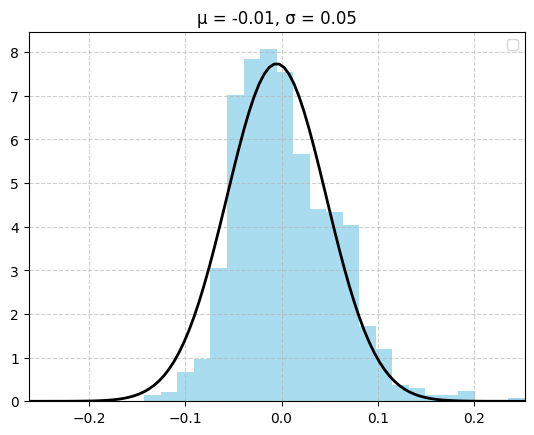

In [55]:
mean, sigma = fit_gaussian2(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    threshold=0.2,
)
plot_gaussian(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    # plot_range=(-np.pi / 2, np.pi / 2),
    mean=mean,
    sigma=sigma,
)

In [40]:
def fastxtMinvx(x, M):
    L = cho_factor(M, lower=True)
    y = cho_solve(L, x)
    return np.dot(x, y)

In [57]:
# f_axion_norm(0.1, R_photon_ring) / f_axion_norm(0.45, R_photon_ring)

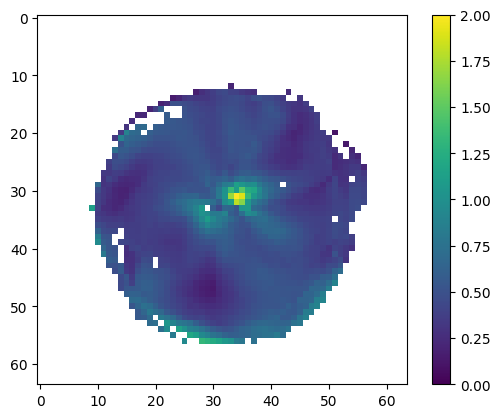

In [58]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase(0.3), axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 2)

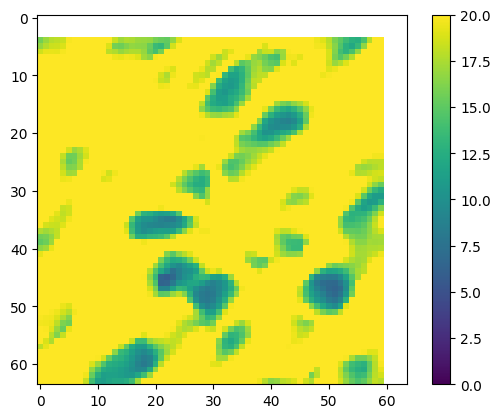

In [41]:
plt.imshow(
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

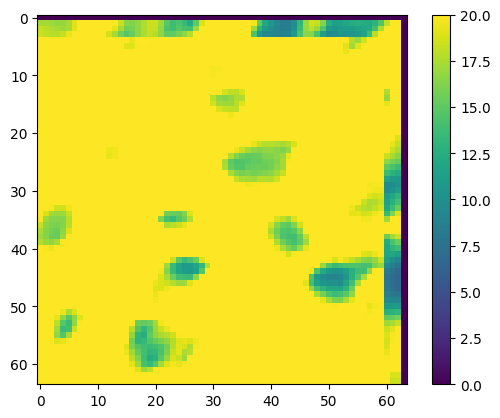

In [ ]:
# old
plt.imshow(
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

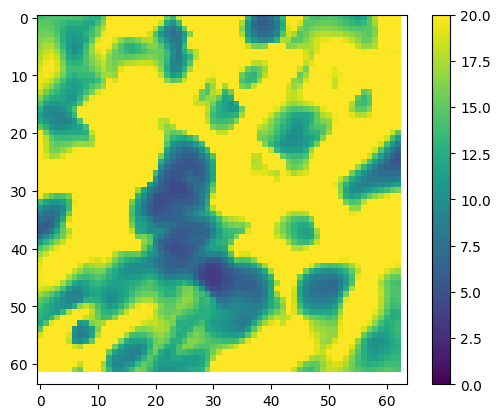

In [42]:
plt.imshow(
    np.sqrt(theta_std[0] * theta_std[0] + theta_std[1] * theta_std[1]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

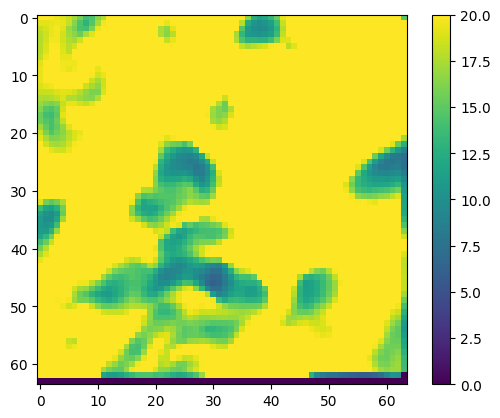

In [ ]:
# old
plt.imshow(
    np.sqrt(theta_std[0] * theta_std[0] + theta_std[1] * theta_std[1]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

In [61]:
if not os.path.exists("Results/figure"):
    os.makedirs("Results/figure")
if not os.path.exists("Results/data"):
    os.makedirs("Results/data")

In [62]:
# plot_gaussian1(
#     theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

In [63]:
# plot_gaussian1(
#     theta_data_786[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

In [64]:
# plt.imshow(std_786[2].reshape(64, 64) / np.pi * 180)

In [65]:
# (
#     np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#     / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
# )[45 * 64 + 31]

In [66]:
# plt.imshow(
#     (
#         np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#         / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
#     ).reshape(64, 64)
# )
# plt.colorbar()
# plt.clim(0.9, 2)

In [67]:
# np.std(theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31])

In [68]:
# plt.plot([np.std(np.sort(theta_data_786[45 * 64 + 31])[de:-de]) for de in range(1, 20)])

In [69]:
np.std(theta_data_786[45 * 64 + 31])

np.float64(0.12045026893499346)

In [ ]:
def get_final_cut(mode="cor_grmhd"):
    # mode: "std", "cor", "cor_grmhd"
    # Delta_theta = [CircleCalc.circle_sub_evpa(theta_mean[1],theta_mean[0]).flatten(),CircleCalc.circle_sub_evpa(theta_mean[3],theta_mean[2]).flatten()] # evpasub
    Delta_theta = [
        CircleCalc.circle_sub_evpa(mean_786[1], mean_786[0]),
        CircleCalc.circle_sub_evpa(mean_786[3], mean_786[2]),
    ]  # evpasub, 但是我们不用
    # Delta_theta = [np.zeros(resolution*resolution),np.zeros(resolution*resolution)]

    # Delta_std =[np.reshape(np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]),4096),np.reshape(np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2]),4096)]
    Delta_std = [
        np.sqrt(std_786[1] * std_786[1] + std_786[0] * std_786[0]),
        np.sqrt(std_786[3] * std_786[3] + std_786[2] * std_786[2]),
    ]
    cor_std = np.asarray([(theta_cor[1] + theta_cor[0]), (theta_cor[3] + theta_cor[2])])
    # cor_std = [theta_cor[1],theta_cor[2]]
    # print(theta_cor[1][1550][1500])

    # generate badset
    print("generating badset...")
    badset_with_large_delta = []  # deepcopy(badset)
    # _tmp_axion_evpa_diffs_16phase_ = np.zeros((64, 64))
    # for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_16phase_1(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_16phase_2(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_std_16phase(alpha), axis=0
    #     )  # just for finding bad pixels
    for l in range(4):
        for i in range(resolution):
            for j in range(resolution):
                # if theta_mean[l][i][j] == 0 and theta_std[l][i][j] == 0:
                if (
                    mean_786[l][i * resolution + j] == 0
                    and std_786[l][i * resolution + j] == 0
                    or np.isnan(mean_786[l][i * resolution + j])
                    or np.isnan(std_786[l][i * resolution + j])
                ):
                    badset_with_large_delta.append(i * resolution + j)

                if condition[i][j]:
                    # if np.isnan(_tmp_axion_evpa_diffs_16phase_[i, j]):
                    #     badset_with_large_delta.append(i * resolution + j)
                    # pass
                    # for lll in range(16):
                    #     diffs_axion_evpa_std_t[lll][i, j] = 1 / 2 / np.pi  # caution
                    #     diffs_axion_evpa_std[i, j] = 1 / 2 / np.pi  # caution
                    # if i <5.5 or j <1.5:
                    #     badset.append(i*resolution+j)
                    pass
                else:
                    badset_with_large_delta.append(i * resolution + j)
            # max_delta_theta=10
            # if Delta_theta[0][i*resolution+j]>max_delta_theta or Delta_theta[1][i*resolution+j]>max_delta_theta or Delta_theta[0][i*resolution+j]<-max_delta_theta or Delta_theta[1][i*resolution+j]<-max_delta_theta:
            #     badset_with_large_delta.append(i*resolution+j)
    if mode == "std":
        for i in range(4096):
            if np.isnan(Delta_std[0][i]) or np.isnan(Delta_std[1][i]):
                badset_with_large_delta.append(i)

    badset_with_large_delta = list(set(badset_with_large_delta))
    print(len(badset_with_large_delta))
    # end generate badset
    print("start calculating final_cut...")

    def getrange():
        return [10, 15, 20, 25, 30, 35, 40, 44]
        # return range(10, 45, 1)

    g_res = 60
    final_cut = [0 for alpha in getrange()]
    # temp_sig = []
    for idx, alpha in enumerate(getrange()):
        tbadset = deepcopy(badset_with_large_delta)
        goodset = list(range(resolution * resolution))
        # c = 0.005

        _tmp_axion_evpa_diffs_16phase_ = np.zeros((64, 64))
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_1(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_2(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_std_16phase(alpha / 100), axis=0
        )  # just for finding bad pixels

        for i in range(resolution):
            for j in range(resolution):
                if np.isnan(_tmp_axion_evpa_diffs_16phase_[i, j]):
                    tbadset.append(i * resolution + j)

        # if omega > 40:
        #     pass
        omega = _omega(alpha / 100)
        print(omega)
        # Fit_result = np.load(
        #     f"GRMHD/data_in/different_omega/{alpha/100}/EVPA_result.npy"
        # )
        # for x in range(len(xy_coord)):
        #     i = int(np.floor(x / 64))
        #     j = x % 64

        #     # * Change P_mean< : 0E9: full image.    0.1E9: 600 pixels.    0.5E9:    150 pixels.            0.9E9: 50 pixels.
        #     # dynamic_cut = 0.15*np.max(I_mean)
        #     dynamic_cut = 0.1e9
        #     if P_mean[1][i][j] < dynamic_cut:
        #         tbadset.append(x)
        #     # if (i-32)*(i-32)+(j-32)*(j-32)>16*16:
        #     #     tbadset.append(x)
        #     if Fit_result[i][j][0] == -3 and Fit_result[i][j][1] == -3:
        #         tbadset.append(x)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        # print(np.mean([((Fit_result[:,:,0])[x//64][x%64]/theta_std[0][x//64][x%64])**2 for x in goodset]))
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 3, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros((resolution, resolution)), np.zeros((resolution, resolution))]
            for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        # llh_astro = np.zeros((g_res, 16))
        # llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_all=[np.asarray(cor_std)+cor_grmhd+np.diag(np.power(np.reshape(diffs_axion_evpa_std_t[i],4096),2)) for i in range(16) ]
        # M_inv = [[get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol])),get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))] for i in range(16)]
        # np.save(f'M_inv_{omega}',M_inv)
        # np.save(f'cor_std',cor_std)
        # print(f"{np.max(M_inv)},{np.min(M_inv)}")
        # print(f"{np.max(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))},{np.min(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))}")

        # amp = np.asarray(Fit_result[:, :, 0])
        # print(amp.mean(), amp.max())
        # ini_phase = np.asarray(Fit_result[:, :, 1])
        # offset = np.asarray(Fit_result[:, :, 2])  # /180*np.pi

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]

        print(np.sort(np.sqrt(np.diag(cor_std_good[0]))) / np.pi * 180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1]))) / np.pi * 180)
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[goodsetrow, goodsetcol]
            tmpCorAxion = [
                np.diag(
                    np.power(
                        np.reshape(
                            axion_evpa_diffs_std_16phase(alpha / 100)[i],
                            4096,
                        ),
                        2,
                    )
                )[goodsetrow, goodsetcol]
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            # print(g)
            M_all = [
                cor_std_good
                + cor_grmhd_good
                + tmpCorAxion[i] * (gagg[g]) ** 2 * b_scaling(alpha / 100) ** 2
                for i in range(16)
            ]
            # M_inv = [[get_inv(M_all[i][0])]*2 for i in range(16)]

            for l in range(16):
                # Delta_theta_theory[l][0] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+ini_phase)/0.1*gagg[g] #?
                # Delta_theta_theory[l][1] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+0.112411*omega/2*24*5+ini_phase)/0.1*gagg[g]
                Delta_theta_theory[l][0] = (
                    axion_evpa_diffs_16phase_1(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][0] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )  # ?
                Delta_theta_theory[l][1] = (
                    axion_evpa_diffs_16phase_2(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][1] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )

                Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0], 4096)
                Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1], 4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] - Delta_theta[k] * 0)[goodset]
                    )

                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[l][k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )
                    # llh_axion[g][l] +=np.exp(0)

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        # print(prgagg[-2])
        final_cut[idx] = (prgagg[g_res - 1] * 0.95 - prgagg[g]) / (
            prgagg[g + 1] - prgagg[g]
        ) * (np.log10(gagg[g + 1]) - np.log10(gagg[g])) + np.log10(gagg[g])
        print(f"{alpha-10} is done!", final_cut[idx])

    plt.plot([alpha * 0.01 for alpha in getrange()], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}.pdf")
    plotting_script([alpha * 0.01 for alpha in getrange()], final_cut, name)
    np.savez(
        f"Results/data/{name}",
        alphas=[alpha * 0.01 for alpha in getrange()],
        cuts=final_cut,
    )
    return final_cut

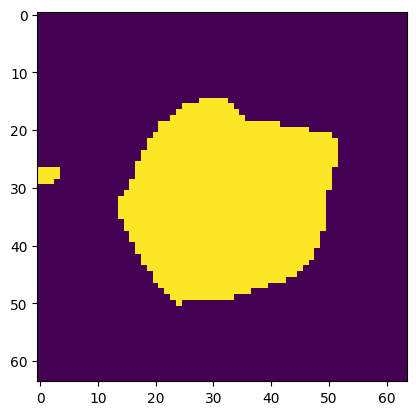

In [ ]:
plt.imshow(
    

generating badset...
3836
start calculating final_cut...
0.09996875
(245, 245)
[ 5.42859298  5.60837627  5.6504007   5.73169604  5.92351154  6.11579796
  6.45770325  6.49922745  6.54227863  6.68846229  7.04558916  7.07610622
  7.11283704  7.22010596  7.23071267  7.26547918  7.26957433  7.35408133
  7.48399547  7.65936237  7.68715652  7.80388215  7.81630862  7.84678438
  7.87867689  7.90244459  7.98591889  8.01909496  8.07484321  8.1127726
  8.14247802  8.22704939  8.24644715  8.24785784  8.26007092  8.38148746
  8.38415916  8.40380062  8.43000236  8.43140581  8.49009372  8.57254521
  8.61826288  8.62606649  8.63504938  8.68341018  8.71797634  8.74121635
  8.77758647  8.77853683  8.79413385  8.79991797  8.82917617  8.84311602
  8.88050234  8.8962576   8.94673775  8.97161941  9.00033433  9.02734664
  9.07325867  9.09610106  9.1622924   9.22391325  9.23148056  9.23860426
  9.24261983  9.29229996  9.31374037  9.34320555  9.36898836  9.50898345
  9.58868717  9.60140182  9.6151895   9.661120

<Figure size 640x480 with 0 Axes>

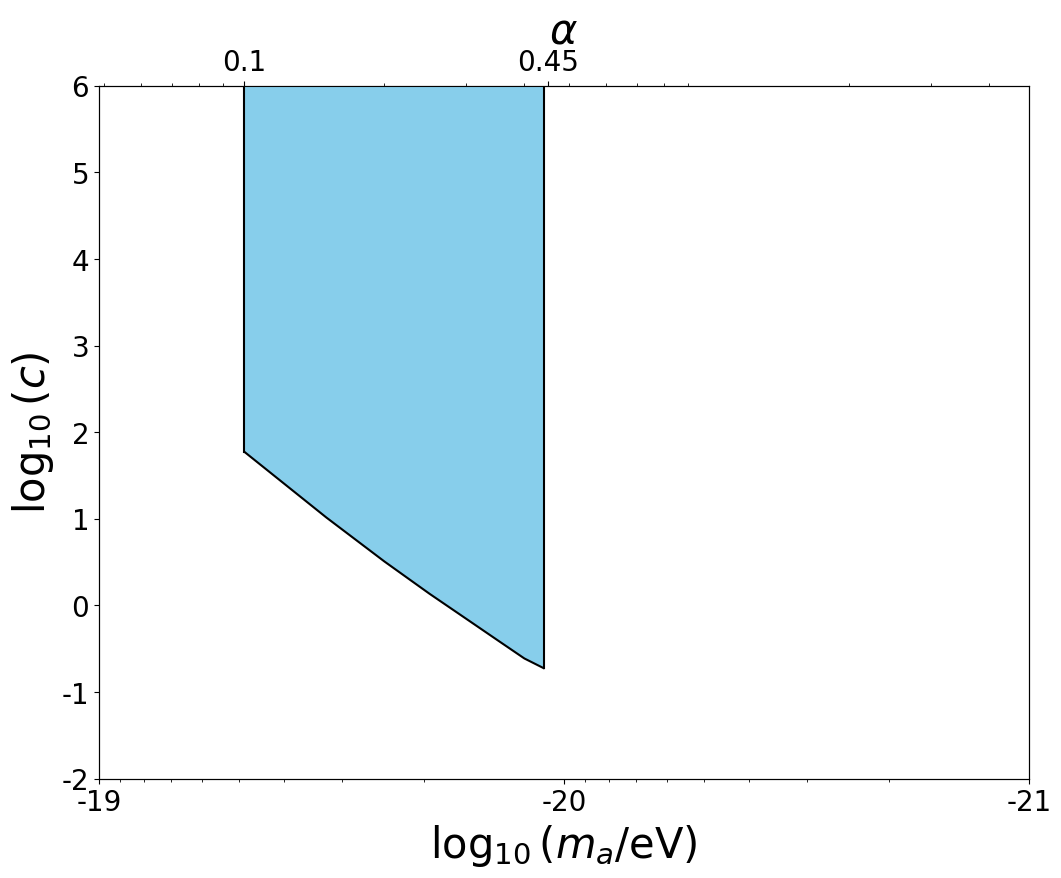

In [71]:
final_cut = get_final_cut(mode="std")

generating badset...
3836
start calculating final_cut...
0.09996875
(245, 245)
[13.72350276 14.05802848 14.10322613 14.25642064 14.4524539  14.48914765
 14.59015183 14.592824   14.63312854 14.63531041 14.65622256 14.69487793
 14.70379071 14.74725167 14.81481514 14.8742171  14.99075344 15.01990498
 15.11386624 15.14644168 15.2251569  15.25672933 15.3891126  15.42827672
 15.52732989 15.62161253 15.74993508 15.84249473 15.84632793 15.92798414
 15.94205543 15.97997645 16.00843691 16.02425323 16.07227618 16.12490474
 16.1936286  16.24166211 16.26360559 16.29039006 16.36751259 16.37460471
 16.43523232 16.44273758 16.44705196 16.45758523 16.543571   16.58193935
 16.6199286  16.64863081 16.68444092 16.72756967 16.81005273 16.82040054
 16.88597076 16.96855339 17.03580831 17.10606292 17.11509847 17.16298047
 17.17916401 17.18591521 17.20078128 17.22101955 17.22725366 17.22958915
 17.24708401 17.31237297 17.33755081 17.49634942 17.50065698 17.57437511
 17.61237256 17.62861594 17.63295187 17.66534

<Figure size 640x480 with 0 Axes>

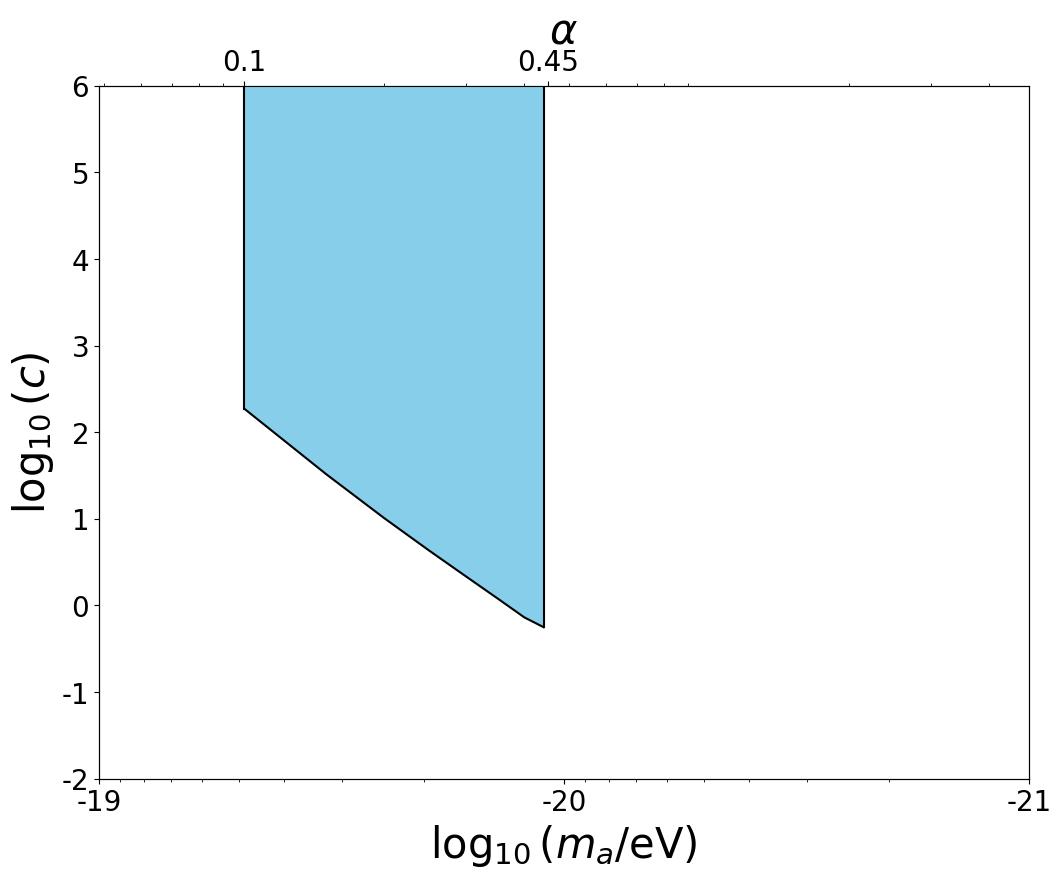

In [72]:
final_cut = get_final_cut(mode="cor")

generating badset...
3181
start calculating final_cut...
0.09996875
(909, 909)
[11.83339997 12.0599553  12.12514568 12.29482653 12.33070819 12.53768764
 12.58054065 12.59731238 12.71858794 12.76765669 12.82158068 12.8479442
 13.10881692 13.16922148 13.20705748 13.35285913 13.58854113 13.83563248
 13.97206636 14.11797845 14.19726906 14.20323673 14.23581345 14.33323855
 14.33892264 14.34137341 14.38497155 14.3953221  14.47634501 14.67620662
 14.71815864 14.77724391 14.8274086  14.93543576 14.94995892 14.97840796
 15.11734187 15.38248472 15.38956183 15.45311478 15.49567153 15.80376005
 15.80381873 15.81087216 15.98350852 15.9860028  16.04675401 16.05135291
 16.13657064 16.16382385 16.18728188 16.22757281 16.29545231 16.3570337
 16.392727   16.51216519 16.54567693 16.54803693 16.56038409 16.56896087
 16.70315306 16.71070447 16.8245973  16.82718937 16.84769283 16.89377008
 16.89880361 16.9020582  16.99716776 17.00070225 17.02179459 17.05936521
 17.05982933 17.1408925  17.18148339 17.1924471

<Figure size 640x480 with 0 Axes>

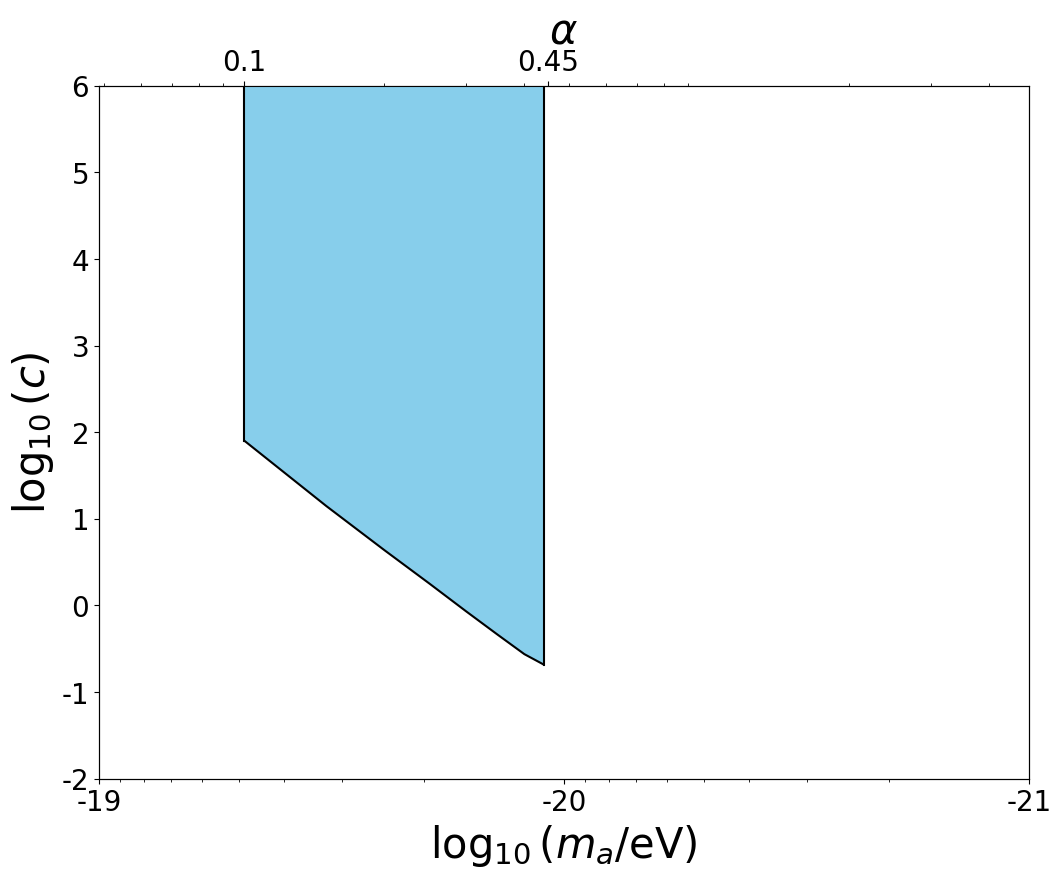

In [155]:
final_cut = get_final_cut(mode="cor_grmhd")

# 1d


In [156]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy

from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel("$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"new_static/{name}.pdf", dpi=600)


theta_mean = []
theta_std = []
theta_cor = []
resolution = 360

num = 0
for day in [95, 96, 100, 101]:
    # with np.load(f'./EHT-Imaging/{day}_1d.npz') as data:
    #     theta_mean.append(data['arr_0'])
    #     theta_std.append(data['arr_1'])

    theta_data = np.load(f"./EHT-Imaging/data_out/{day}_EVPA_1d.npy")
    # _tmp_sub = CircleCalc.circle_sub_evpa(theta_data,theta_mean[num])
    # # cor_data = np.dot(_tmp_sub.T,_tmp_sub)/_tmp_sub.shape[0]
    # cor_data = np.dot(_tmp_sub[np.argsort(sum_of_pixels)[:786],:].T,_tmp_sub[np.argsort(sum_of_pixels)[:786],:])/_tmp_sub.shape[0]
    # theta_cor.append(cor_data)
    theta_data_1d_786 = theta_data[np.argsort(sum_of_pixels)[:786]]
    theta_data_1d_786_vonmises_mean = np.apply_along_axis(
        vonmises_mean, 0, theta_data_1d_786
    )
    theta_data_1d_786 = (
        CircleCalc.circle_sub_evpa(theta_data_1d_786, theta_data_1d_786_vonmises_mean)
        + theta_data_1d_786_vonmises_mean
    )
    tmpres = np.apply_along_axis(
        fit_gaussian2,
        0,
        theta_data_1d_786,
        plot_failed=False,
        angle=True,
        lower_bound=-np.pi / 2,
        upper_bound=np.pi / 2,
        bins=100,
        threshold=0.2,
    )
    theta_mean.append(tmpres[0])
    theta_std.append(tmpres[1])
    cor_data = CircleCalc.circle_sub_evpa(theta_data_1d_786, tmpres[0]).T
    theta_cor.append(np.dot(cor_data, cor_data.T) / 786)
    num += 1

xy_coord = [i for i in range(resolution)]
Delta_theta = [theta_mean[1] - theta_mean[0], theta_mean[3] - theta_mean[2]]
# Delta_theta = [np.zeros(resolution),np.zeros(resolution)]
Delta_std = [
    np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]),
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]),
]
cor_std = np.asarray([theta_cor[1] + theta_cor[0], theta_cor[3] + theta_cor[2]])

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_222742/783820196.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_222742/783820196.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


In [157]:
def get_final_cut_1d(mode="cor_grmhd"):
    badset = []
    # cor_std = [theta_cor[0],theta_cor[2]]
    # _tmp_axion_evpa_diffs_16phase_1d_ = np.zeros((360,))
    # for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_16phase_1(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_16phase_2(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_std_16phase(alpha), axis=0
    #     )  # just for finding bad pixels
    for i in range(resolution):
        for l in range(4):
            if (
                theta_mean[l][i] == 0
                and theta_std[l][i] == 0
                or np.isnan(theta_mean[l][i])
                or np.isnan(theta_std[l][i])
                # or np.isnan(_tmp_axion_evpa_diffs_16phase_1d_[i])
            ):
                badset.append(i)
    badset = list(set(badset))

    def getrange():
        return [10, 15, 20, 25, 30, 35, 40, 44]
        # return range(10, 45, 1)

    g_res = 60
    final_cut = [0 for alpha in getrange()]
    for idx, alpha in enumerate(getrange()):
        tbadset = deepcopy(badset)
        goodset = list(range(resolution))

        _tmp_axion_evpa_diffs_16phase_1d_ = np.zeros((360,))
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_16phase_1(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_16phase_2(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_std_16phase(alpha / 100), axis=0
        )  # just for finding bad pixels
        for i in range(resolution):
            if np.isnan(_tmp_axion_evpa_diffs_16phase_1d_[i]):
                tbadset.append(i)

        # c = 0.005
        omega = _omega(alpha / 100)
        # Fit_result = np.load(
        #     f"GRMHD/data/different_omega/{omega}/EVPA_phi_10deg_result.npy"
        # )
        tbadset = list(np.unique(tbadset))
        minbadset_x = 0
        minbadset_count = 360
        for testx in range(10):
            _tbetset = deepcopy(tbadset)
            for i in range(resolution):
                if i % 10 != testx:
                    _tbetset.append(i)
            _tbetset = list(np.unique(_tbetset))
            if len(_tbetset) < minbadset_count:
                minbadset_count = len(_tbetset)
                minbadset_x = testx
        print(minbadset_x, minbadset_count)
        for i in range(resolution):
            if np.round(i % 10) != minbadset_x:  # point最多
                tbadset.append(i)
            # if Fit_result[i][0] == -3 and Fit_result[i][1] == -3:
            #     tbadset.append(i)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 3, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros(resolution), np.zeros(resolution)] for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        # llh_astro = np.zeros((g_res, 16))
        # llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_inv = [get_inv(np.asarray(cor_std[0][goodsetrow,goodsetcol])),get_inv(np.asarray(cor_std[1][goodsetrow,goodsetcol]))]
        # np.save(f'M_inv_{omega}_1d',M_inv)
        # np.save(f'cor_std_1d',cor_std)

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]
        print(np.sort(np.sqrt(np.diag(cor_std_good[0]))) / np.pi * 180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1]))) / np.pi * 180)
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[
                goodsetrow, goodsetcol
            ]  # 虽然这里的grmhd是4096x4096的矩阵，但反正取的是360x360内所以无所谓
            tmpCorAxion = [
                np.diag(np.power(axion_evpa_1d_diffs_std_16phase(alpha / 100)[i], 2))[
                    goodsetrow, goodsetcol
                ]
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            M_all = [
                cor_std_good
                + cor_grmhd_good
                + tmpCorAxion[i] * (gagg[g]) ** 2 * b_scaling(alpha / 100) ** 2
                for i in range(16)
            ]
            for l in range(16):
                # amp = np.asarray(Fit_result[:, 0])
                # ini_phase = np.asarray(Fit_result[:, 1])
                # offset = np.asarray(Fit_result[:, 2])
                Delta_theta_theory[l][0] = (
                    axion_evpa_1d_diffs_16phase_1(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                Delta_theta_theory[l][1] = (
                    axion_evpa_1d_diffs_16phase_2(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][0] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )
                # Delta_theta_theory[l][1] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )

                # Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0],4096)
                # Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1],4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] - Delta_theta[k] * 0)[goodset]
                    )
                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        final_cut[idx] = (prgagg[g_res - 1] * 0.95 - prgagg[g]) / (
            prgagg[g + 1] - prgagg[g]
        ) * (np.log10(gagg[g + 1]) - np.log10(gagg[g])) + np.log10(gagg[g])
        print(f"{idx} is done!")
    plt.plot([alpha * 0.01 for alpha in getrange()], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}_1d.pdf")
    plotting_script([alpha * 0.01 for alpha in getrange()], final_cut, name)
    np.savez(
        f"Results/data/{name}_1d",
        alphas=[alpha * 0.01 for alpha in getrange()],
        cuts=final_cut,
    )
    return final_cut

0 324
(36, 36)
[ 5.21487656  5.7659036   6.84766078  7.79660423  8.52340294  8.6137462
  9.01280855 10.74852927 10.88443695 10.97411327 11.32682624 11.41967506
 11.93681455 12.38865949 12.69062796 13.46266515 15.10208871 15.49077183
 15.5185751  18.01629641 20.26227109 20.3777847  20.79925258 21.09499698
 22.21819934 26.65383032 28.94873691 32.48968416 39.64991266 46.28353674
 46.73102619 48.59402814 50.73496522 52.45546564 56.43226236 57.55626882]
[ 6.90307384 10.65211077 11.51603667 11.64028817 11.72422202 12.21947205
 13.95423452 14.87883825 15.70826235 18.08788309 19.53312488 20.06343443
 20.69839914 20.87836839 21.53654051 21.548195   24.18154945 25.7520154
 27.38690166 29.46921585 30.00835148 30.54403724 32.00913864 35.75292394
 36.12435991 38.03763055 40.18842764 41.82355832 42.13619659 44.11152089
 47.63021314 48.2605022  48.9117125  51.25385686 57.09154987 58.40617663]
0 is done!
0 324
(36, 36)
[ 5.21487656  5.7659036   6.84766078  7.79660423  8.52340294  8.6137462
  9.0128085

[np.float64(2.169587991028501),
 np.float64(1.416271852692996),
 np.float64(0.9096741431144002),
 np.float64(0.533043986872649),
 np.float64(0.21803815291703643),
 np.float64(-0.05084923550691285),
 np.float64(-0.2727107030024437),
 np.float64(-0.3897598569874572)]

<Figure size 640x480 with 0 Axes>

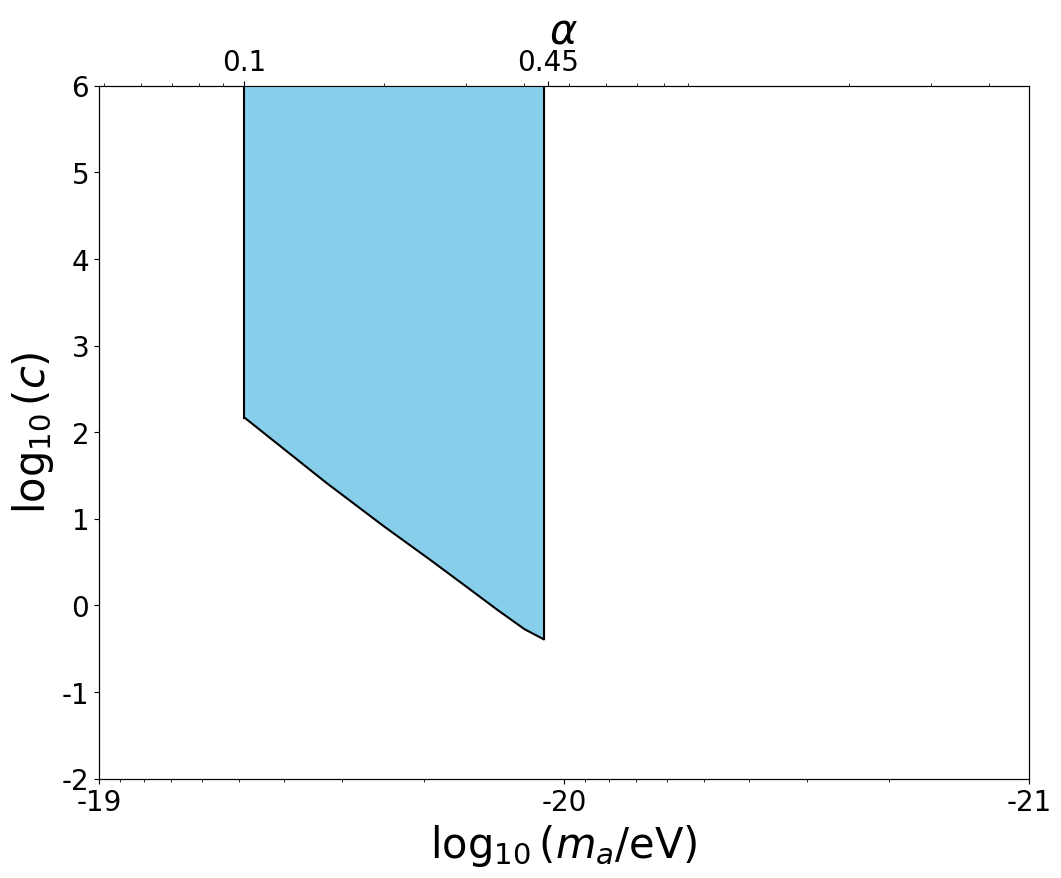

In [158]:
get_final_cut_1d(mode="std")

0 324
(36, 36)
[ 9.34807755 10.07470436 10.48403336 10.91847279 11.29078565 11.60461147
 12.53748922 13.53397283 13.73890807 14.02600165 14.05465295 14.3493732
 14.51718309 16.08402973 16.12119905 16.62796258 22.34646295 22.84875886
 22.84980927 23.91124211 26.02035811 28.93283379 31.11284233 33.36115252
 33.95200289 36.2091021  40.48127934 43.44620645 43.48844397 44.97273081
 46.30358183 46.78586746 48.37407302 48.65720883 51.93094095 52.12762957]
[13.32827584 15.52452506 16.15370853 16.92632329 20.71297908 21.81481112
 25.11140982 25.16510297 25.96799926 28.39611205 30.92088282 33.30337061
 34.08993697 34.82567285 36.85948095 37.32784651 37.85833458 38.91378026
 39.55095916 41.27509697 41.88261917 43.07068185 43.31355458 43.73153911
 44.10069083 44.59878504 45.32478629 45.41808937 45.70711278 46.02359885
 47.69715039 48.46694449 48.58353819 48.98144033 49.30420226 53.36856811]
0 is done!
0 324
(36, 36)
[ 9.34807755 10.07470436 10.48403336 10.91847279 11.29078565 11.60461147
 12.53748

[np.float64(2.352660175378871),
 np.float64(1.598723652481917),
 np.float64(1.0921995501499078),
 np.float64(0.7109148685555742),
 np.float64(0.3944848311246675),
 np.float64(0.12368440954141059),
 np.float64(-0.10015221871318095),
 np.float64(-0.22249974301158548)]

<Figure size 640x480 with 0 Axes>

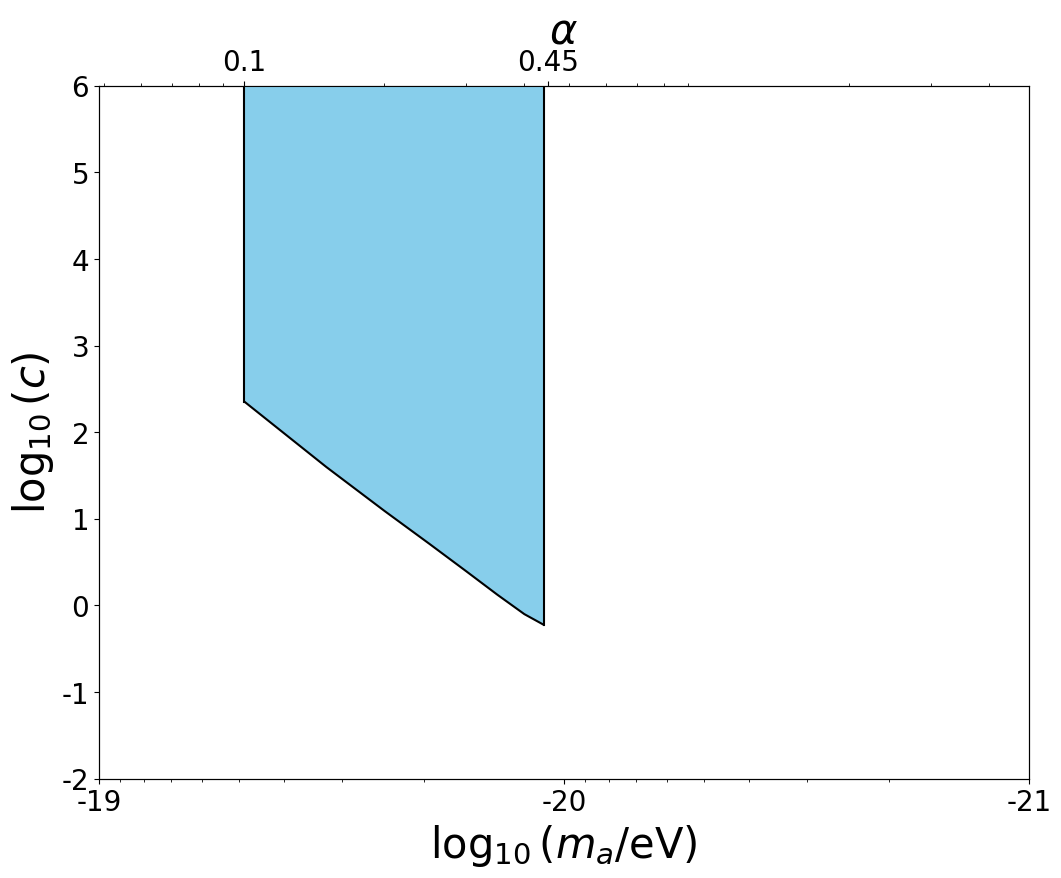

In [159]:
get_final_cut_1d(mode="cor")

0 324
(36, 36)
[ 9.34807755 10.07470436 10.48403336 10.91847279 11.29078565 11.60461147
 12.53748922 13.53397283 13.73890807 14.02600165 14.05465295 14.3493732
 14.51718309 16.08402973 16.12119905 16.62796258 22.34646295 22.84875886
 22.84980927 23.91124211 26.02035811 28.93283379 31.11284233 33.36115252
 33.95200289 36.2091021  40.48127934 43.44620645 43.48844397 44.97273081
 46.30358183 46.78586746 48.37407302 48.65720883 51.93094095 52.12762957]
[13.32827584 15.52452506 16.15370853 16.92632329 20.71297908 21.81481112
 25.11140982 25.16510297 25.96799926 28.39611205 30.92088282 33.30337061
 34.08993697 34.82567285 36.85948095 37.32784651 37.85833458 38.91378026
 39.55095916 41.27509697 41.88261917 43.07068185 43.31355458 43.73153911
 44.10069083 44.59878504 45.32478629 45.41808937 45.70711278 46.02359885
 47.69715039 48.46694449 48.58353819 48.98144033 49.30420226 53.36856811]
0 is done!
0 324
(36, 36)
[ 9.34807755 10.07470436 10.48403336 10.91847279 11.29078565 11.60461147
 12.53748

[np.float64(2.364756436701155),
 np.float64(1.6113315315212722),
 np.float64(1.104787620350387),
 np.float64(0.7217023208804381),
 np.float64(0.40771669646861897),
 np.float64(0.1388476457649601),
 np.float64(-0.08674486797574713),
 np.float64(-0.20722532171968167)]

<Figure size 640x480 with 0 Axes>

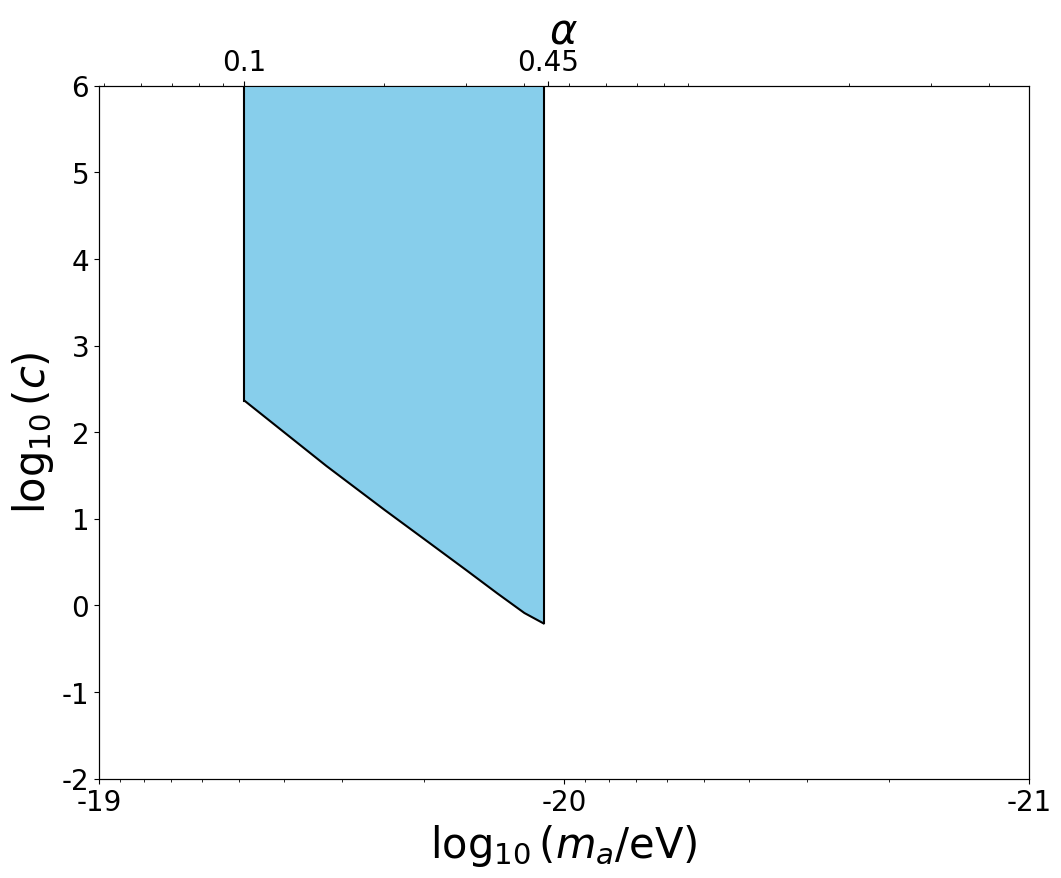

In [160]:
get_final_cut_1d(mode="cor_grmhd")

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.7563888 , 13.45154066, 26.38031961, 31.96265062, 21.22161131,
       18.93035074, 24.15504967, 26.65206932, 34.72027064, 19.61024197,
       14.58457443, 22.79992831, 20.15230603, 10.83766744, 10.34497303,
       11.43059054,  8.3288432 ])

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.43107396, 15.33082919, 29.91254594, 29.67396822, 24.92765656,
       19.30193136, 19.63667278, 25.56671903, 30.88545625, 34.37667603,
       23.72729762, 17.86171389, 15.92704258, 24.62061043,  7.95199034,
        9.91025657, 11.0482334 ,  9.84320908,  8.95129117, 10.55465118,
        7.60775649,  9.84547076])

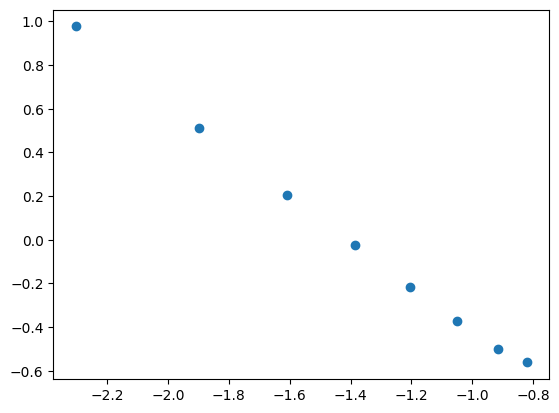

In [87]:
plt.scatter(np.log(np.array([0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44])), final_cut)

In [207]:
final_cut

[np.float64(1.5028934084145136),
 np.float64(1.3939294101656103),
 np.float64(1.2984880164334047),
 np.float64(1.219521044625946),
 np.float64(1.1228947218706897),
 np.float64(1.0545351709889288),
 np.float64(0.9830719027876236),
 np.float64(0.9113186129136752),
 np.float64(0.8586672714176375),
 np.float64(0.7920957763987064),
 np.float64(0.7399947843873623),
 np.float64(0.6892863898285836),
 np.float64(0.6364081696191491),
 np.float64(0.5964752515228422),
 np.float64(0.5433239255800661),
 np.float64(0.4976455755368914),
 np.float64(0.4546506037196992),
 np.float64(0.40851450500056574),
 np.float64(0.37482212559147965),
 np.float64(0.3284562287731632),
 np.float64(0.2921153171488353),
 np.float64(0.2554134588560792),
 np.float64(0.21612976050799518),
 np.float64(0.1850722515333471),
 np.float64(0.1482043316761318),
 np.float64(0.11782979958308852),
 np.float64(0.08324602656325561),
 np.float64(0.05424944300450993),
 np.float64(0.030452466188061765),
 np.float64(-0.0037480913606893432),

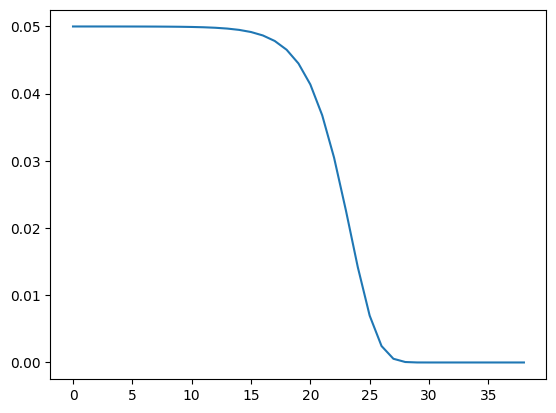

In [231]:
plt.plot(np.diff(prgagg))

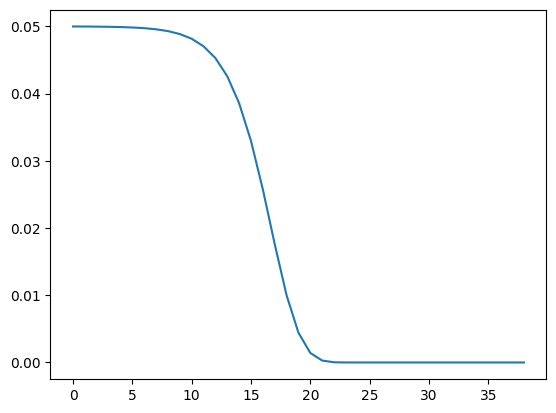

In [228]:
plt.plot(np.diff(prgagg))

In [79]:
final_cut1 = np.load("Results/data/cor_grmhd_1d.npz")
final_cut2 = np.load("Results/data/cor_grmhd.npz")

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_222742/2604238203.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_222742/2604238203.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


<Figure size 640x480 with 0 Axes>

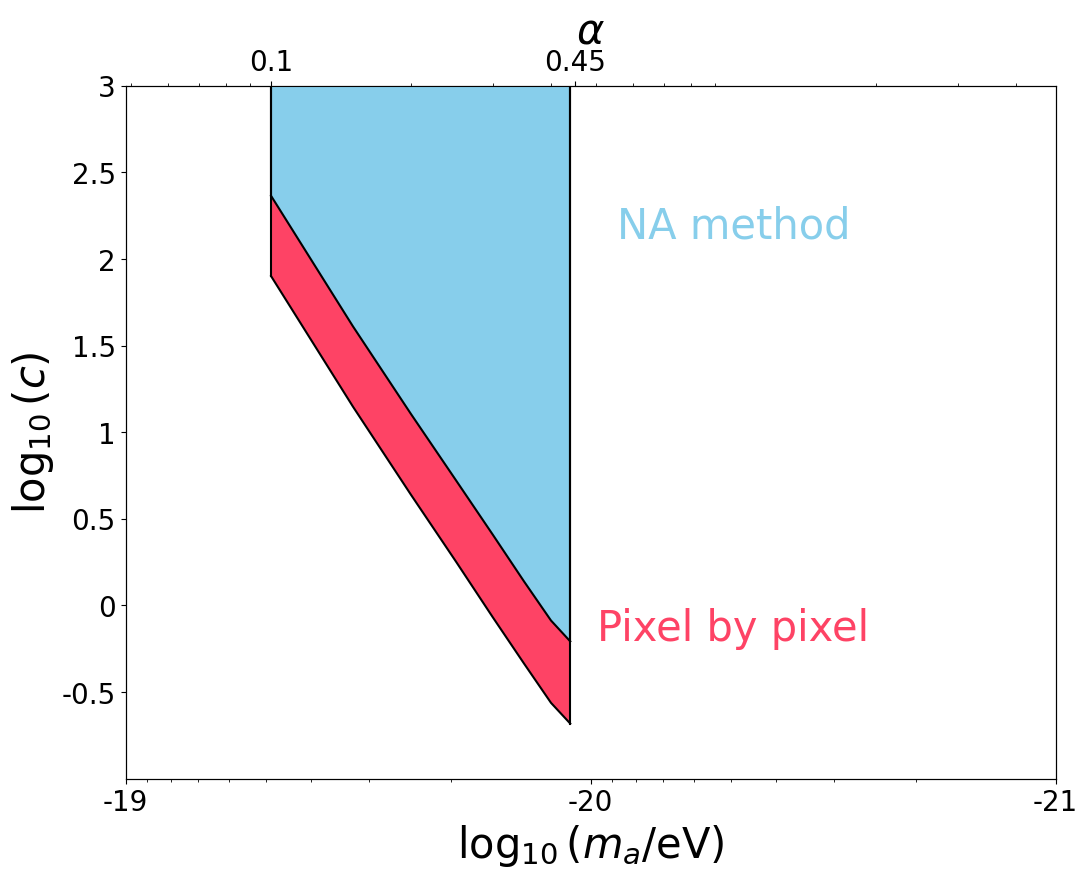

In [82]:
plt.clf()
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax.set_ylim(-1, 3)
ax.set_yticks([-0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3])
ax.set_yticklabels(["-0.5", "0", "0.5", "1", "1.5", "2", "2.5", "3"], size=20)
ax.set_ylabel("$\log_{10}(c)$", size=30)
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels(["0.1", "0.45"], size=20)
ax2.set_xlabel(r"$ \alpha $", size=30)
ax2.set_xlim(0.0486495, 4.86495)
ax.set_xlim(1e-19, 1e-21)
ax.set_xticks([1e-21, 1e-20, 1e-19])
ax.set_xticklabels(["-21", "-20", "-19"], size=20)
ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
temp = np.load("new_static/l_cor_1d.npz")
# x1 = temp["omegas"]
# y1 = temp["cuts"]
x1 = final_cut1["alphas"]
y1 = final_cut1["cuts"]
yarray1 = deepcopy(y1)
temp = np.load("M_all/new_static/l_cor_dyn_obs.npz")
# x2 = temp["omegas"]
# y2 = temp["cuts"]
x2 = final_cut2["alphas"]
y2 = final_cut2["cuts"]
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1, yarray1, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray1[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray1[0], 6], "black")
ax2.plot(x2, yarray2, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray2[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray2[0], 6], "black")
xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
ax2.fill_between(x1, yarray1, 3, ls="-", lw=2, fc=xcolor[0], alpha=1)
ax2.fill_between(x1, yarray2, yarray1, ls="-", lw=2, fc=xcolor[2], alpha=1)
plt.annotate(
    "NA method",
    xy=(0.78, 0.78),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[0],
)
plt.annotate(
    "Pixel by pixel",
    xy=(0.8, 0.2),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[2],
)
plt.savefig(f"new_static/contract.pdf", dpi=600)

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_177838/1386927692.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_177838/1386927692.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


<Figure size 640x480 with 0 Axes>

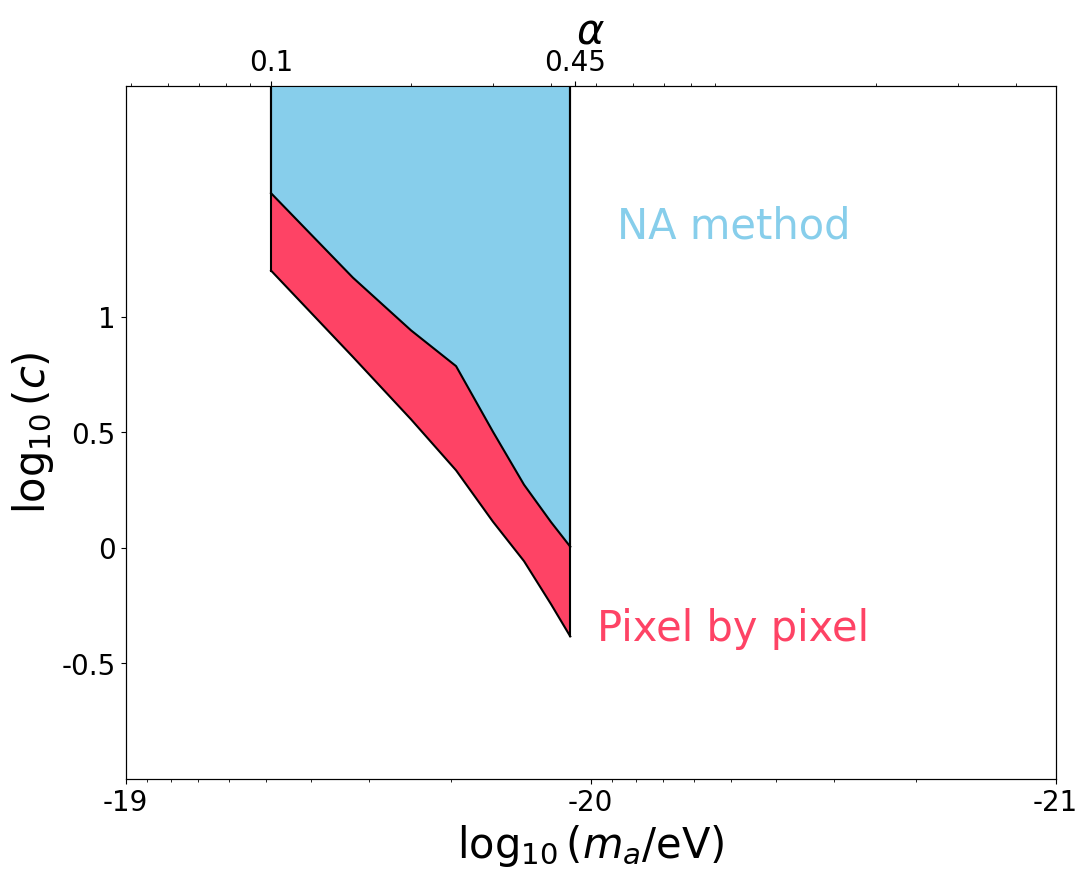

In [77]:
plt.clf()
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax.set_ylim(-1, 2)
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_yticklabels(["-0.5", "0", "0.5", "1"], size=20)
ax.set_ylabel("$\log_{10}(c)$", size=30)
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels(["0.1", "0.45"], size=20)
ax2.set_xlabel(r"$ \alpha $", size=30)
ax2.set_xlim(0.0486495, 4.86495)
ax.set_xlim(1e-19, 1e-21)
ax.set_xticks([1e-21, 1e-20, 1e-19])
ax.set_xticklabels(["-21", "-20", "-19"], size=20)
ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
temp = np.load("new_static/l_cor_1d.npz")
# x1 = temp["omegas"]
# y1 = temp["cuts"]
x1 = final_cut1["alphas"]
y1 = final_cut1["cuts"]
yarray1 = deepcopy(y1)
temp = np.load("M_all/new_static/l_cor_dyn_obs.npz")
# x2 = temp["omegas"]
# y2 = temp["cuts"]
x2 = final_cut2["alphas"]
y2 = final_cut2["cuts"]
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1, yarray1, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray1[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray1[0], 6], "black")
ax2.plot(x2, yarray2, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray2[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray2[0], 6], "black")
xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
ax2.fill_between(x1, yarray1, 3, ls="-", lw=2, fc=xcolor[0], alpha=1)
ax2.fill_between(x1, yarray2, yarray1, ls="-", lw=2, fc=xcolor[2], alpha=1)
plt.annotate(
    "NA method",
    xy=(0.78, 0.78),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[0],
)
plt.annotate(
    "Pixel by pixel",
    xy=(0.8, 0.2),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[2],
)
plt.savefig(f"new_static/contract.pdf", dpi=600)

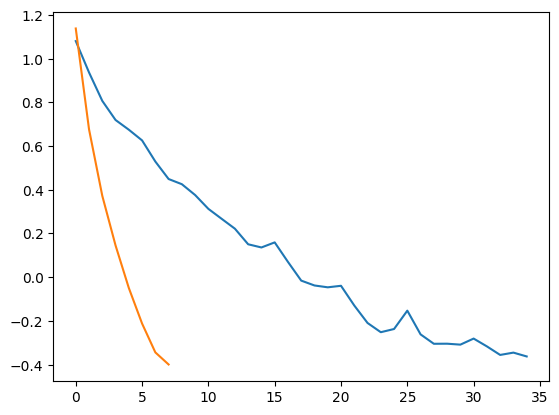

In [64]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

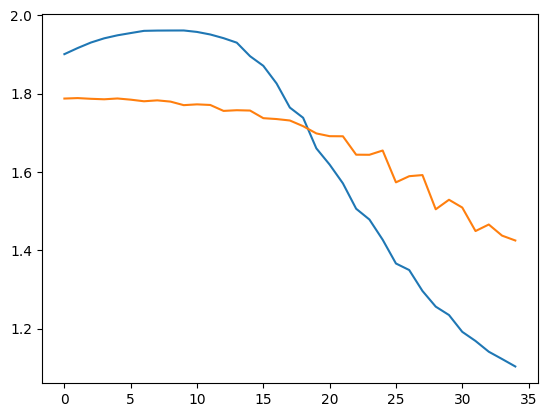

In [160]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

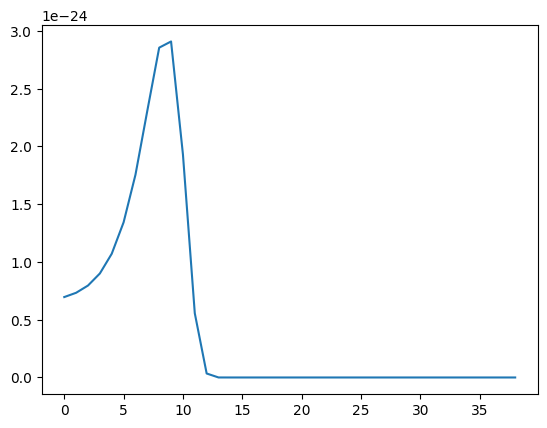

In [32]:
plt.plot(np.diff(prgagg))

In [ ]:
final_cut[34] - final_cut[0]

np.float64(-1.3126400088088257)

In [ ]:
All_data = np.load(f"./EHT-Imaging/101_all_data.npy")
theta_data101 = 0.5 * np.arctan2(
    np.mean(All_data[:, :, :, 2], axis=0), np.mean(All_data[:, :, :, 1], axis=0)
)  # rad

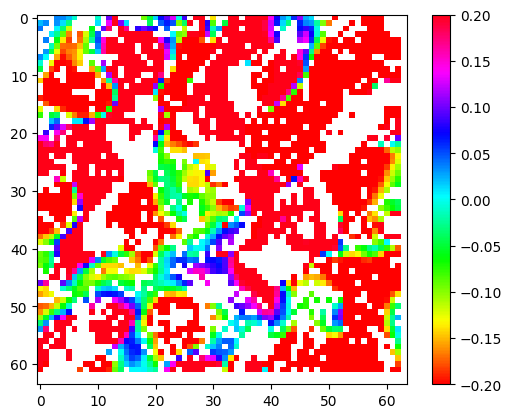

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_mean[1], theta_mean[0]), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

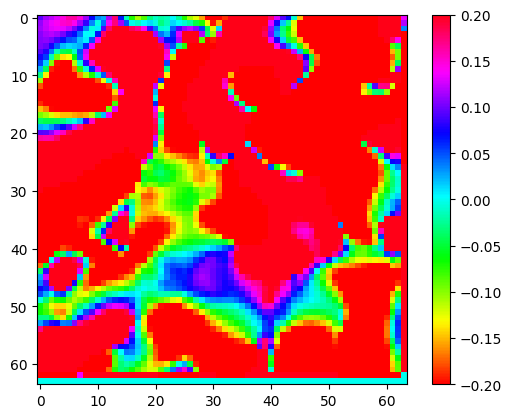

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_data96, theta_data95), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

In [ ]:
jj = theta_mean[1] - theta_mean[0]
jj[np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]) > 0.3] = np.nan

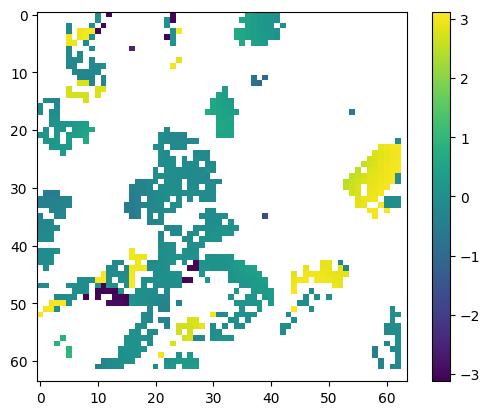

In [137]:
plt.imshow(jj)
plt.colorbar()
# plt.clim(-0.2,0.2)

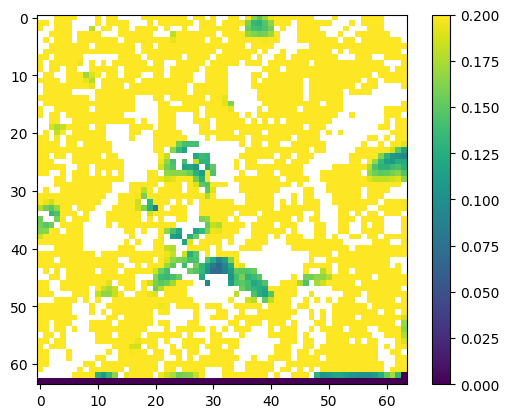

In [ ]:
plt.imshow(np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]))
plt.colorbar()
plt.clim(0, 0.2)

In [ ]:
cor_std_good[0, 1, 1]

np.float64(0.4512943525439286)

In [ ]:
(np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[:, goodsetrow, goodsetcol])[
    0
].min()

np.float64(0.0)

In [ ]:
jj = np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[
    :, goodsetrow, goodsetcol
]

In [ ]:
np.array([jj[1, i, i] for i in range(237)]).min()

np.float64(0.11598372425616639)

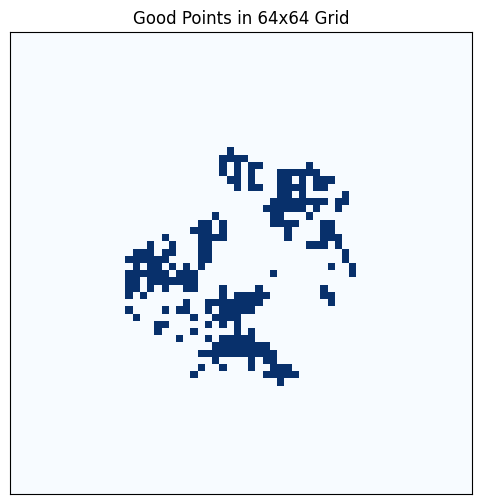

In [ ]:
grid = np.zeros((64, 64))

# 把 goodset 里的点设为 1
for num in goodset:
    x, y = divmod(num, 64)
    grid[x, y] = 1

# 画图
plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap="Blues", origin="upper")  # 颜色用蓝色
plt.xticks([])
plt.yticks([])
plt.title("Good Points in 64x64 Grid")
plt.show()

In [ ]:
[cor_std + cor_grmhd + tmpCorAxion[i] * (gagg[g] * gagg[g]) for i in range(16)]

[array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ..., nan, nan,  0.],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [ 0.,  0.,  0., ..., nan, nan, nan]]]),
 array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ...,

In [83]:
final_cut

[np.float64(1.501703368559929),
 np.float64(1.4906423571358534),
 np.float64(1.4007462096465821),
 np.float64(1.2690943382366104),
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [ ]:
theta_data_1d_786[theta_data_1d_786 > np.pi / 2] -= np.pi
theta_data_1d_786[theta_data_1d_786 < -np.pi / 2] += np.pi

In [ ]:
np.save("Plot/theta_data_1d_786_4", theta_data_1d_786)